## TAIL RISK MODEL FOR 15 YEARS of NIFTY50 DATA USING EVT


### Historic Simulation

In [2]:
import pandas as pd
import numpy as np
df=pd.read_csv('Nifty 50 Historical Data.csv')

In [3]:
df["Price"] = df["Price"].astype(str).str.replace(r"[^\d.]", "", regex=True).astype(float)
# Calculating log return using consecutive closing prices
df["log_returns"] = np.log(df["Price"] / df["Price"].shift(1))

# Dropping the first row since it will be NaN (no previous day to compare to)
df = df.dropna(subset=["log_returns"])
df.head()

,Date,Price,Open,High,Low,Vol.,Change %,log_returns
1,06-10-2026,22776.10,"22,603.25","22,776.10","22,561.60",328.80M,0.98%,0.007627
2,05-10-2026,22555.75,"22,532.40","22,621.80","22,397.10",436.66M,0.60%,-0.009722
3,01-10-2026,22421.95,"22,543.70","22,610.60","22,217.30",463.55M,-0.88%,-0.005950
4,30-09-2026,22620.45,"22,665.00","22,809.35","22,595.20",378.96M,-0.42%,0.008814
5,29-09-2026,22716.20,"22,732.45","22,753.25","22,569.65",603.19M,-0.28%,0.004224


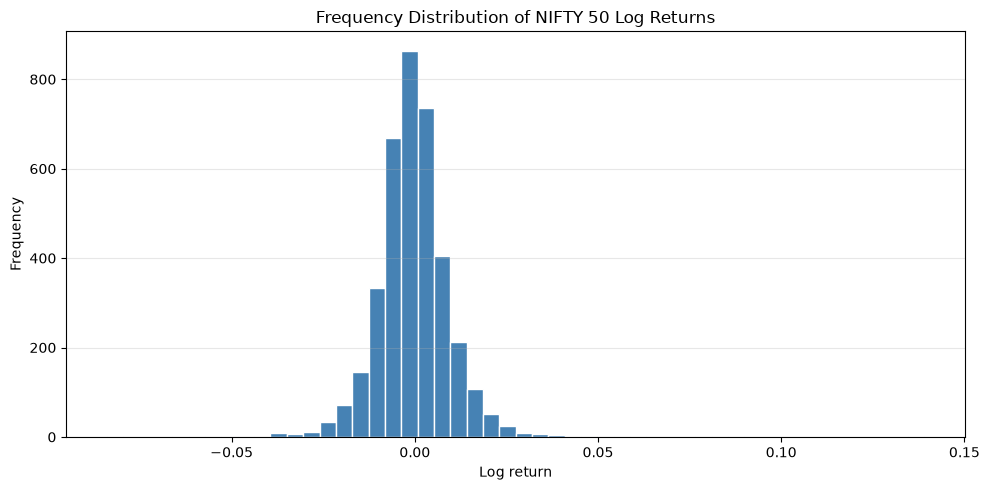

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df["log_returns"], bins=50, color="steelblue", edgecolor="white")
ax.set(title="Frequency Distribution of NIFTY 50 Log Returns", xlabel="Log return", ylabel="Frequency")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

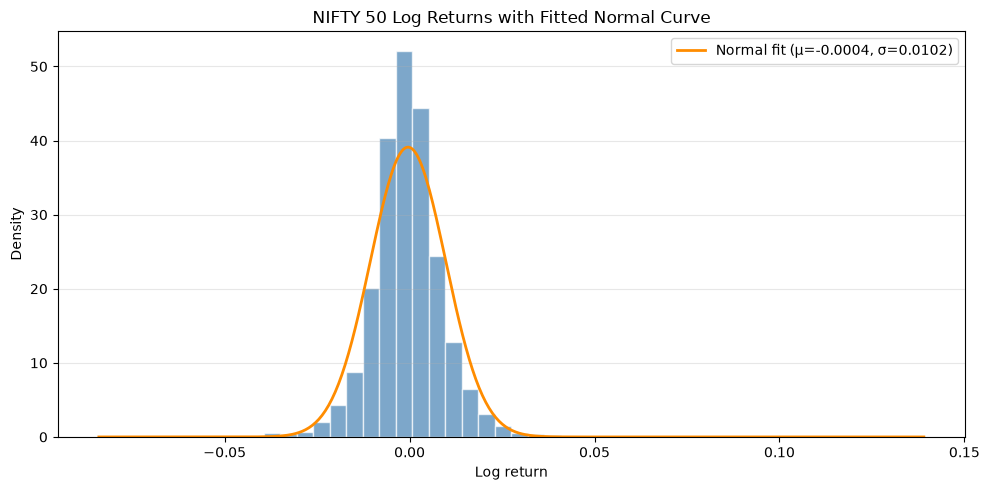

In [15]:
returns = df["log_returns"]
mu, sigma = returns.mean(), returns.std(ddof=1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(returns, bins=50, density=True, color="steelblue", edgecolor="white", alpha=0.7)
x = np.linspace(returns.min(), returns.max(), 500)
normal_curve = np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))
ax.plot(x, normal_curve, color="darkorange", linewidth=2, label=f"Normal fit (μ={mu:.4f}, σ={sigma:.4f})")

ax.set(title="NIFTY 50 Log Returns with Fitted Normal Curve",
    xlabel="Log return", ylabel="Density")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
from statistics import NormalDist

alpha = 0.001
z = NormalDist().inv_cdf(alpha)
phi = np.exp(-0.5 * z**2) / np.sqrt(2 * np.pi)

var_99 = -(mu + sigma * z)
cvar_99 = -(mu - sigma * phi / alpha)

print(f"99% VaR:  {var_99:.2%}")
print(f"99% CVaR: {cvar_99:.2%}")

99% VaR:  3.19%
99% CVaR: 3.48%


In [19]:
historical_cutoff = returns.quantile(alpha)
var_99_historical = -historical_cutoff
cvar_99_historical = -returns[returns <= historical_cutoff].mean()

print(f"Historical 99% VaR:  {var_99_historical:.2%}")
print(f"Historical 99% CVaR: {cvar_99_historical:.2%}")

Historical 99% VaR:  4.79%
Historical 99% CVaR: 6.42%


In [20]:
from scipy.stats import t

df_t, loc_t, scale_t = t.fit(returns)
q_t = t.ppf(alpha, df_t)

var_t = -(loc_t + scale_t * q_t)

# Expected shortfall for the lower tail of a Student's t distribution
cvar_t = -(
    loc_t
    - scale_t
    * ((df_t + q_t**2) / (df_t - 1))
    * t.pdf(q_t, df_t)
    / alpha
)

print(f"Fitted degrees of freedom: {df_t:.2f}")
print(f"Student's t VaR at {1 - alpha:.1%}:  {var_t:.2%}")
print(f"Student's t CVaR at {1 - alpha:.1%}: {cvar_t:.2%}")

Fitted degrees of freedom: 2.38
Student's t VaR at 99.9%:  9.59%
Student's t CVaR at 99.9%: 16.51%
